# 01 — Analyse exploratoire des données (EDA)

Challenge NPS — IBM Telco Customer Churn v11.1.3+ (multi-tables, avec
`Satisfaction Score`).

Ce notebook couvre : les distributions et valeurs manquantes du dataset
analytique, la distribution du label NPS (variante baseline vs.
bruitée), et le croisement Satisfaction x Churn qui illustre pourquoi
les colonnes de churn sont blacklistées du jeu de features.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path("..") / "src"))
import config

pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110
np.random.seed(config.SEED)

labeled = pd.read_parquet(config.LABELED_DATASET_PATH)
print(labeled.shape)
labeled.head()


(7043, 53)


,Customer ID,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Satisfaction Score,Customer Status,Churn Label,Churn Value,Churn Score,CLTV,Churn Category,Churn Reason,Age,Under 30,Number of Dependents,Referred a Friend,Number of Referrals,Offer,Avg Monthly Long Distance Charges,Internet Type,Avg Monthly GB Download,Streaming Music,Unlimited Data,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Population,NPS Category,NPS Category Noisy,NPS Category Code,NPS Category Noisy Code
0,3668-QPYBK,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,Churned,Yes,1,86,3239,Competitor,Competitor made better offer,37,No,0,No,0,NaN,10.47,DSL,21,No,Yes,0.0,0,20.94,129.09,58198,Detractor,Detractor,0,0
1,9237-HQITU,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,2,Churned,Yes,1,67,2701,Other,Moved,19,Yes,2,No,0,NaN,9.12,Fiber Optic,51,No,Yes,0.0,0,18.24,169.89,43019,Detractor,Detractor,0,0
2,9305-CDSKC,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,3,Churned,Yes,1,86,5372,Other,Moved,31,No,2,No,0,NaN,12.15,Cable,26,Yes,Yes,0.0,0,97.20,917.70,62784,Detractor,Detractor,0,0
3,7892-POOKP,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,3,Churned,Yes,1,84,5003,Other,Moved,23,Yes,3,No,0,Offer C,4.89,Fiber Optic,47,Yes,Yes,0.0,0,136.92,3182.97,1957,Detractor,Detractor,0,0
4,0280-XJGEX,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,Churned,Yes,1,89,5340,Competitor,Competitor had better devices,38,No,1,No,0,NaN,44.33,Fiber Optic,11,Yes,Yes,0.0,0,2172.17,7208.47,15140,Detractor,Detractor,0,0


## 1. Vue d'ensemble

In [2]:
labeled.dtypes.value_counts()


str         29
int64       14
float64      8
category     2
Name: count, dtype: int64

In [3]:
labeled.describe(include="number").T


,count,mean,std,min,25%,50%,75%,max
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7043.0,2279.734304,2266.794470,0.000000,398.550000,1394.550000,3786.600000,8684.800000
Satisfaction Score,7043.0,3.244924,1.201657,1.000000,3.000000,3.000000,4.000000,5.000000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.505040,21.170031,5.000000,40.000000,61.000000,75.500000,96.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


## 2. Valeurs manquantes

Les seules colonnes manquantes sont des absences **structurelles** (pas
des données manquantes au sens strict) :
- `Churn Category` / `Churn Reason` : vides pour les clients qui n'ont pas
  churné (colonnes blacklistées de toute façon, jamais utilisées comme
  features).
- `Offer` : vide quand le client n'a pas souscrit d'offre promotionnelle.
- `Internet Type` : vide quand le client n'a pas de service internet.

Le seul vrai retraitement effectué est celui de `Total Charges`, qui
était une chaîne vide pour les 11 clients avec `Tenure Months == 0`
(nouveaux clients sans encore de facture) — corrigé dans
`src/make_dataset.py` en le mettant à 0, avant même l'écriture du
parquet (donc invisible ici, mais documenté dans `docs/decisions.md`).


In [ ]:
missing = labeled.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing


Churn Category    5174
Churn Reason      5174
Offer             3877
Internet Type     1526
dtype: int64

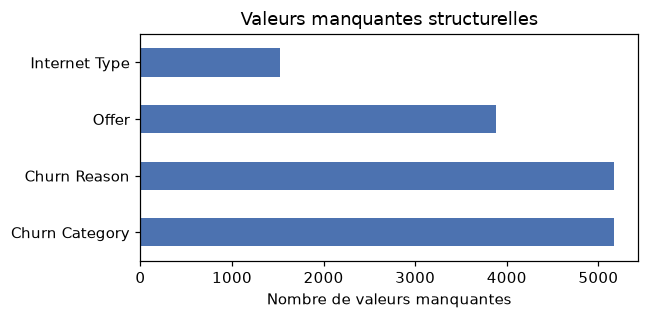

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
missing.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Nombre de valeurs manquantes")
ax.set_title("Valeurs manquantes structurelles")
plt.tight_layout()
plt.show()


## 3. Distribution du label NPS

Rappel du mapping baseline (`config.SATISFACTION_TO_NPS`) :
Satisfaction Score 5 -> Promoter, 4 -> Passive, <=3 -> Detractor.

On compare la variante baseline et la variante bruitée (~10% de
réassignations vers une classe ordinale adjacente), qui servira de test
de sensibilité en phase 2.


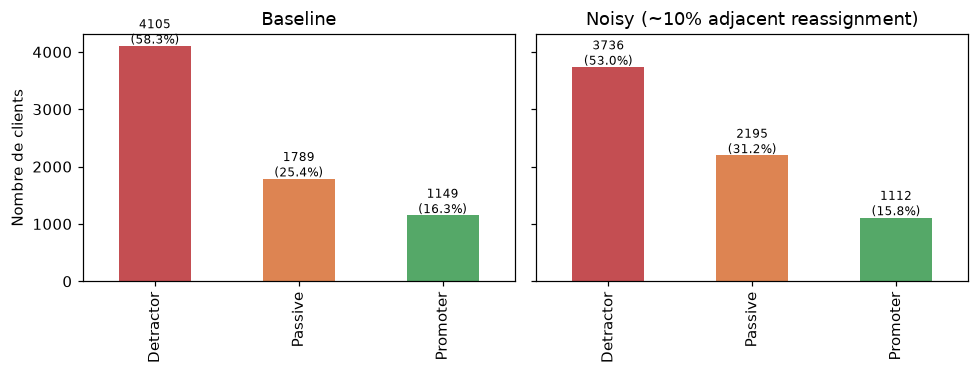

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, col, title in zip(
    axes,
    [config.TARGET_COL, config.TARGET_COL_NOISY],
    ["Baseline", "Noisy (~10% adjacent reassignment)"],
):
    counts = labeled[col].value_counts().reindex(config.NPS_CATEGORIES)
    counts.plot(kind="bar", ax=ax, color=["#C44E52", "#DD8452", "#55A868"])
    ax.set_title(title)
    ax.set_xlabel("")
    for i, v in enumerate(counts):
        ax.text(i, v + 40, f"{v}\n({v / len(labeled):.1%})", ha="center", fontsize=8)
axes[0].set_ylabel("Nombre de clients")
plt.tight_layout()
plt.show()


Le déséquilibre est marqué (~58% de Detractors, ~16% de Promoters), ce
qui justifie la règle #5 du challenge (class_weight / seuils plutôt que
resampling par défaut) et l'exigence de métriques robustes au
déséquilibre (QWK, macro-F1, balanced accuracy, rappel par classe).


## 4. Distributions des features clés

Quelques variables numériques et catégorielles structurantes, croisées
avec le label NPS baseline pour une première lecture métier.


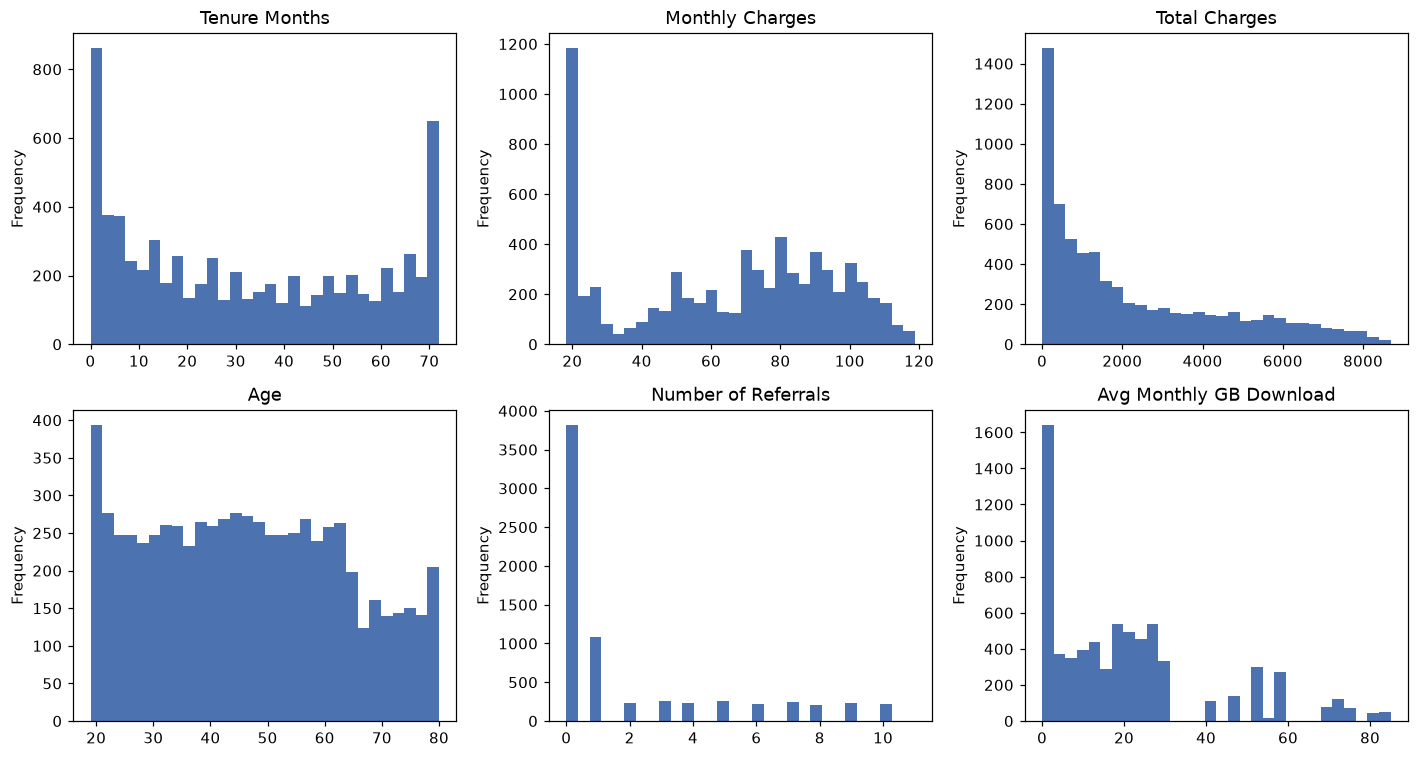

In [7]:
numeric_cols = ["Tenure Months", "Monthly Charges", "Total Charges", "Age",
                "Number of Referrals", "Avg Monthly GB Download"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    labeled[col].plot(kind="hist", bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.show()


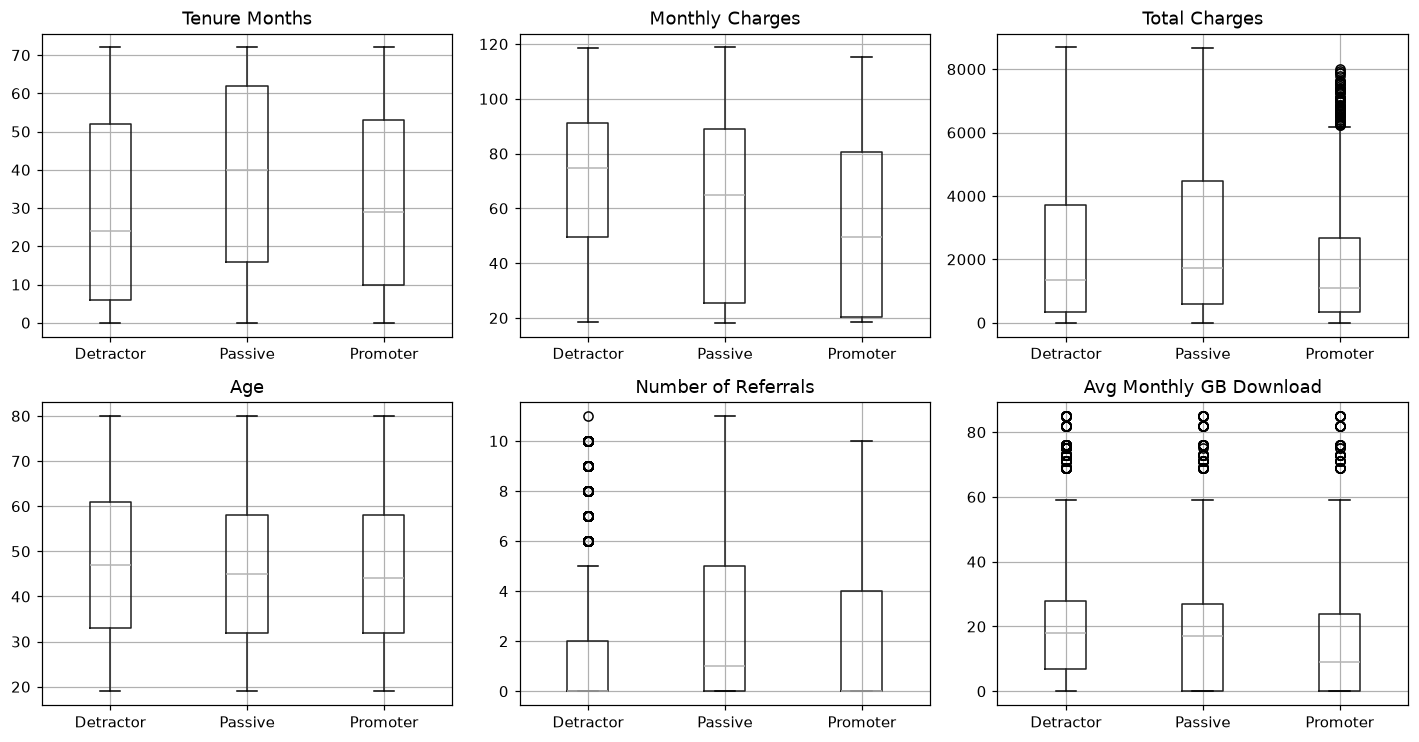

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    labeled.boxplot(column=col, by=config.TARGET_COL, ax=ax,
                     positions=range(len(config.NPS_CATEGORIES)))
    ax.set_xticks(range(len(config.NPS_CATEGORIES)))
    ax.set_xticklabels(config.NPS_CATEGORIES)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


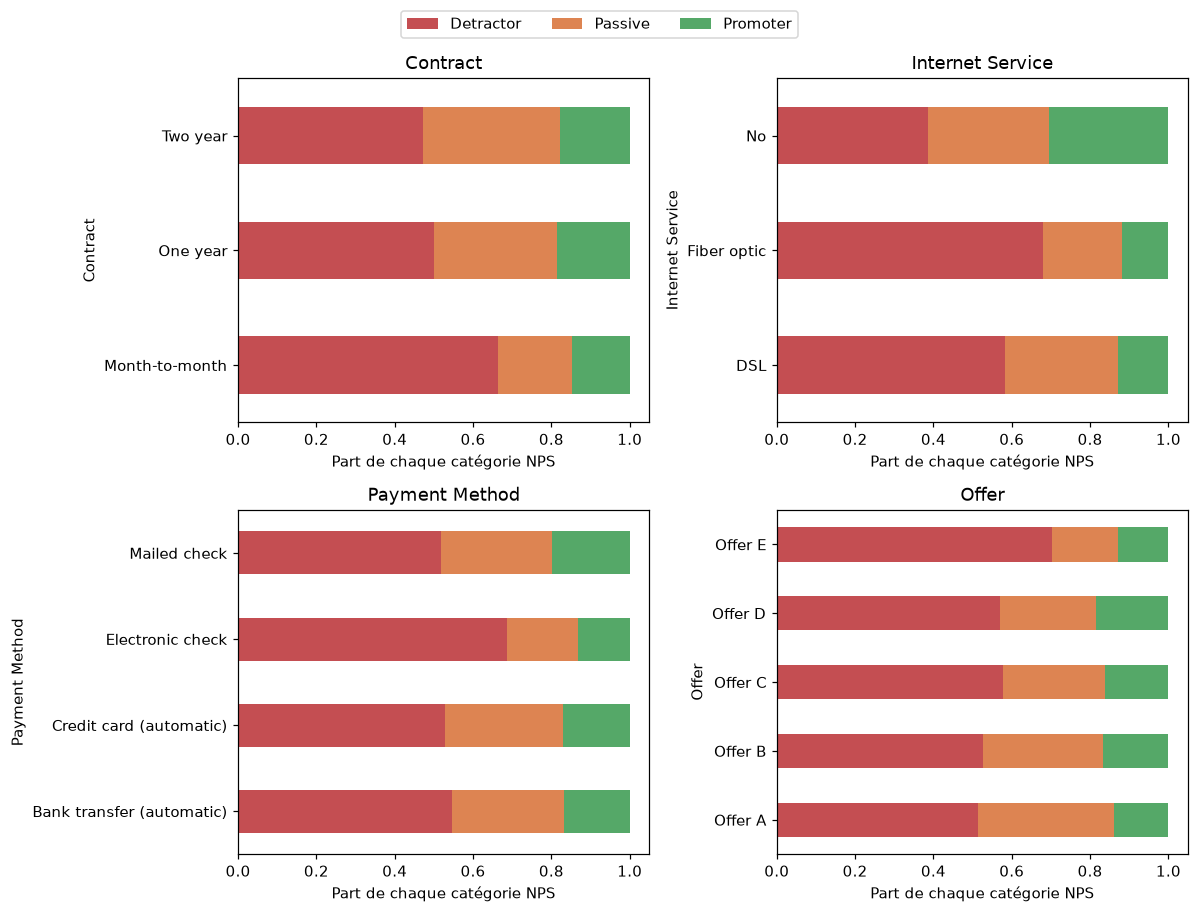

In [9]:
categorical_cols = ["Contract", "Internet Service", "Payment Method", "Offer"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), categorical_cols):
    ct = pd.crosstab(labeled[col], labeled[config.TARGET_COL], normalize="index")
    ct = ct[config.NPS_CATEGORIES]
    ct.plot(kind="barh", stacked=True, ax=ax,
            color=["#C44E52", "#DD8452", "#55A868"], legend=False)
    ax.set_title(col)
    ax.set_xlabel("Part de chaque cat\u00e9gorie NPS")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()


## 5. Croisement Satisfaction x Churn — illustration du leakage

`Satisfaction Score` est la source du label (rule #1). Les colonnes
`Churn Value` / `Churn Label` / `Churn Score` sont **fortement**
corrélées à `Satisfaction Score` par construction (un client très
insatisfait a une probabilité de churn beaucoup plus élevée), ce qui en
ferait des prédicteurs quasi triviaux du label si on les laissait entrer
dans les features — d'où leur exclusion systématique
(`config.LEAKAGE_BLACKLIST`).


In [10]:
ct = pd.crosstab(labeled["Satisfaction Score"], labeled["Churn Value"])
ct.columns = ["Not churned (0)", "Churned (1)"]
ct


,Not churned (0),Churned (1)
Satisfaction Score,,
1,0,922
2,0,518
3,2236,429
4,1789,0
5,1149,0


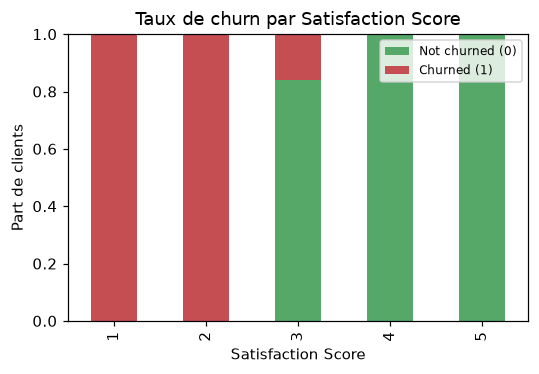

In [11]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ct_pct = ct.div(ct.sum(axis=1), axis=0)
ct_pct.plot(kind="bar", stacked=True, ax=ax, color=["#55A868", "#C44E52"])
ax.set_ylabel("Part de clients")
ax.set_title("Taux de churn par Satisfaction Score")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


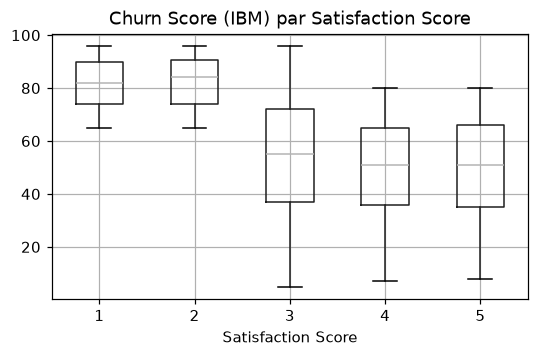

                    Satisfaction Score  Churn Score  Churn Value
Satisfaction Score            1.000000    -0.495144    -0.754649
Churn Score                  -0.495144     1.000000     0.660772
Churn Value                  -0.754649     0.660772     1.000000


In [12]:
fig, ax = plt.subplots(figsize=(5, 3.5))
labeled.boxplot(column="Churn Score", by="Satisfaction Score", ax=ax)
plt.suptitle("")
ax.set_title("Churn Score (IBM) par Satisfaction Score")
plt.tight_layout()
plt.show()
print(labeled[["Satisfaction Score", "Churn Score", "Churn Value"]].corr(numeric_only=True))


Le taux de churn chute mécaniquement à mesure que `Satisfaction Score`
augmente, et `Churn Score` (le score de risque de churn calculé par IBM)
est fortement corrélé à `Satisfaction Score`. Ces colonnes ne
franchiront jamais la frontière du feature engineering.


## 6. Aperçu des deux splits d'évaluation

Comparaison de la distribution du label NPS baseline entre les
répondants du split "réaliste" (biais de réponse : faible satisfaction +
forte ancienneté) et le split aléatoire stratifié de contrôle.


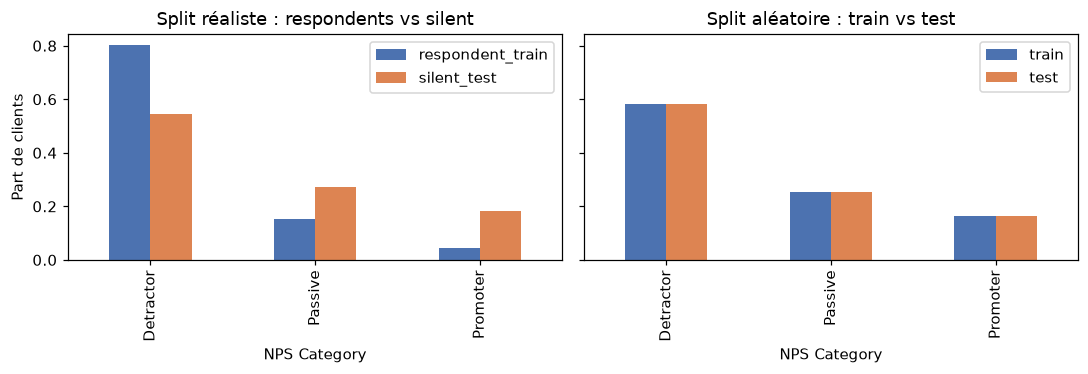

In [13]:
realistic = pd.read_parquet(config.REALISTIC_SPLIT_PATH)
random_split = pd.read_parquet(config.RANDOM_SPLIT_PATH)

df_r = labeled.merge(realistic, on=config.ID_COL)
df_s = labeled.merge(random_split, on=config.ID_COL)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

dist_realistic = pd.DataFrame({
    seg: df_r.loc[df_r["split"] == seg, config.TARGET_COL]
        .value_counts(normalize=True).reindex(config.NPS_CATEGORIES)
    for seg in ["respondent_train", "silent_test"]
})
dist_realistic.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Split r\u00e9aliste : respondents vs silent")

dist_random = pd.DataFrame({
    seg: df_s.loc[df_s["split"] == seg, config.TARGET_COL]
        .value_counts(normalize=True).reindex(config.NPS_CATEGORIES)
    for seg in ["train", "test"]
})
dist_random.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Split al\u00e9atoire : train vs test")

for ax in axes:
    ax.set_ylabel("Part de clients")
plt.tight_layout()
plt.show()


Le split réaliste montre l'effet attendu : les répondants sont sur-
représentés en Detractors (biais de réponse simulé), tandis que la
population silencieuse (le vrai périmètre de scoring) est beaucoup plus
équilibrée. C'est précisément l'écart que le protocole d'évaluation
métier (rule #4) est censé mesurer — un modèle entraîné uniquement sur
les répondants doit être validé sur cette population silencieuse, pas
sur un simple hold-out aléatoire.

## Prochaines étapes (phase 2)
- Feature engineering (`src/features.py`) en excluant systématiquement
  `config.LEAKAGE_BLACKLIST`.
- Modélisation ordinale (`mord`, LightGBM avec objectif ordinal ou
  multi-classe + class_weight), évaluée avec `src/evaluate.py` (QWK,
  macro-F1, balanced accuracy, rappel par classe, lift Detractor,
  calibration).
- Comparaison split réaliste vs split aléatoire pour quantifier l'écart
  de performance dû au biais de réponse.
